# Island–unit crosswalk investigation

A read-only diagnostic for deciding whether an island-only simplification experiment is justified. It does **not** create masks, regenerate networks, or run routing.

The notebook answers four questions:

1. Which dry components are actually filled by the current unit variants?
2. Which units share the same (or nearly the same) island fills?
3. Which unit collapses bundle several distinct islands?
4. Which islands are suitable candidates for a future paired unit-versus-island routing pilot?

## Important interpretation

`boundary_component_labels` are **land-component labels**, built for two-bank width measurement. They include true islands as well as mainland-connected banks and bars. A separate label is therefore a useful starting point, not sufficient proof of an island-routing treatment. The eligibility flags below are deliberately conservative.

In [1]:
from __future__ import annotations

from collections import Counter
from pathlib import Path
import json
import re

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize, shapes
from rasterio.windows import Window, from_bounds
from scipy.ndimage import find_objects, label as nd_label
from shapely.geometry import shape as shapely_shape
from shapely.strtree import STRtree

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_colwidth', 120)

In [2]:
# Change only these two settings to inspect another completed independent-unit experiment.
EXAMPLE_ID = '41'
EXPERIMENT_DIR = Path(f'/Volumes/PhD/river_hierarchy/network_variants/output/{EXAMPLE_ID}_indep__anchored')

if not EXPERIMENT_DIR.exists():
    raise FileNotFoundError(f'Experiment directory not found: {EXPERIMENT_DIR}')

STATES_DIR = EXPERIMENT_DIR / 'states'
BASE_DIR = STATES_DIR / 'S000_base'
BASE_HIERARCHY = BASE_DIR / 'hierarchy'
BASE_VARIANT = BASE_DIR / 'variant'

print('Experiment:', EXPERIMENT_DIR)
print('State directories:', len([p for p in STATES_DIR.iterdir() if p.is_dir()]))

Experiment: /Volumes/PhD/river_hierarchy/network_variants/output/41_indep__anchored
State directories: 137


In [3]:
unit_summary = pd.read_csv(BASE_HIERARCHY / 'unit_summary.csv')
path_metrics = pd.read_csv(BASE_HIERARCHY / 'path_metrics.csv')
unit_membership = pd.read_csv(BASE_VARIANT / 'summary' / 'unit_link_membership.csv')
ranking = pd.read_csv(BASE_HIERARCHY / 'collapse_ranking.csv')
registry = pd.read_csv(EXPERIMENT_DIR / 'state_registry.csv')

base_links_path = next((BASE_VARIANT / 'directed').glob('*directed_links.gpkg'))
base_links = gpd.read_file(base_links_path)

print(f'Base network: {len(base_links)} links; {len(unit_summary)} detected units.')
print(registry['status'].value_counts(dropna=False).to_string())

Base network: 409 links; 136 detected units.
status
complete    137


## Collect realised unit-fill geometries

Each `edit/add` polygon is a dry component that the existing unit treatment actually filled. This avoids inferring candidates from a huge raster before establishing which components are relevant to the present design.

In [4]:
def unit_id_from_state(path: Path) -> int:
    match = re.fullmatch(r'S\d+_unit_(\d+)', path.name)
    if match is None:
        raise ValueError(f'Not an independent-unit state: {path.name}')
    return int(match.group(1))

records = []
for state_dir in sorted(STATES_DIR.glob('S*_unit_*')):
    edit_path = state_dir / 'variant' / 'mask' / 'collapse_edit_geometries.gpkg'
    if not edit_path.exists():
        continue
    edits = gpd.read_file(edit_path)
    adds = edits.loc[edits.get('action', pd.Series(index=edits.index, dtype=object)).eq('add')].copy()
    if adds.empty:
        adds = edits.loc[edits.get('action', pd.Series(index=edits.index, dtype=object)).isin(['add', 'fill'])].copy()
    for edit_index, row in adds.iterrows():
        if row.geometry is None or row.geometry.is_empty:
            continue
        records.append({
            'state_id': state_dir.name,
            'unit_id': unit_id_from_state(state_dir),
            'edit_index': int(edit_index),
            'area_m2': float(row.geometry.area),
            'perimeter_m': float(row.geometry.length),
            'geometry': row.geometry,
        })

fills = gpd.GeoDataFrame(records, geometry='geometry', crs=base_links.crs)
fills['area_km2'] = fills['area_m2'] / 1e6
fills['compactness'] = np.where(
    fills['perimeter_m'] > 0, 4 * np.pi * fills['area_m2'] / fills['perimeter_m'] ** 2, np.nan
)
print(f'{len(fills)} realised fill polygons from {fills.unit_id.nunique()} unit variants.')
fills[['unit_id', 'edit_index', 'area_km2', 'compactness']].sort_values('area_km2', ascending=False).head(10)

185 realised fill polygons from 136 unit variants.


,unit_id,edit_index,area_km2,compactness
176,126,6,59.403422,0.250115
184,33,3,27.028257,0.227020
169,121,2,21.945717,0.380373
178,95,2,11.555153,0.399422
182,26,2,11.011932,0.515112
107,109,0,10.784335,0.172224
181,69,0,10.589678,0.074087
180,54,0,9.914653,0.129922
179,113,0,9.127210,0.224092
147,129,3,8.023968,0.239748


In [5]:
# Unit -> number and total area of separately filled components.
unit_fill_summary = (
    fills.groupby('unit_id', as_index=False)
    .agg(n_filled_components=('edit_index', 'size'), total_fill_area_km2=('area_km2', 'sum'),
         largest_fill_area_km2=('area_km2', 'max'))
    .merge(unit_summary[['unit_id', 'class', 'n_paths', 'compound_bubble_id', 'is_compound']], on='unit_id', how='left')
    .merge(ranking[['unit_id', 'collapse_order_global', 'collapse_priority_score']], on='unit_id', how='left')
    .sort_values(['n_filled_components', 'total_fill_area_km2'], ascending=False)
)
display(unit_fill_summary.head(20))
print('Distribution of independently filled components per current unit:')
print(unit_fill_summary['n_filled_components'].value_counts().sort_index().to_string())

,unit_id,n_filled_components,total_fill_area_km2,largest_fill_area_km2,class,n_paths,compound_bubble_id,is_compound,collapse_order_global,collapse_priority_score
125,126,6,60.768194,59.403422,compound_or_nested_complex,6,37,True,130,0.222222
35,36,6,3.148965,1.943391,compound_or_nested_complex,5,15,True,117,0.281481
21,22,5,2.155795,1.962722,compound_or_nested_complex,6,20,True,122,0.266667
128,129,4,11.775270,8.023968,compound_or_nested_complex,5,36,True,119,0.275926
14,15,4,10.828975,7.166117,compound_or_nested_complex,5,23,True,121,0.268519
131,132,4,5.500076,3.783434,compound_or_nested_complex,7,37,True,100,0.344444
74,75,4,2.583669,2.230456,compound_or_nested_complex,7,25,True,114,0.290741
10,11,3,3.852245,3.481624,compound_or_nested_complex,4,23,True,125,0.248148
46,47,3,0.467899,0.297482,compound_or_nested_complex,3,17,True,22,0.738889
32,33,2,27.136032,27.028257,compound_or_nested_complex,3,23,True,136,0.042593


Distribution of independently filled components per current unit:
n_filled_components
1    108
2     19
3      2
4      4
5      1
6      2


## Deduplicate and crosswalk fills

Exact geometry equality is too strict because two unit footprints can clip the same island slightly differently. The relation below treats two fills as the same island candidate when either one covers at least 95% of the other. Review borderline matches on the map before using this as a final count.

In [6]:
def build_fill_clusters(frame: gpd.GeoDataFrame, coverage_threshold: float = 0.95) -> pd.DataFrame:
    geoms = list(frame.geometry)
    tree = STRtree(geoms)
    parent = list(range(len(frame)))

    def find(index):
        while parent[index] != index:
            parent[index] = parent[parent[index]]
            index = parent[index]
        return index

    def union(left, right):
        left, right = find(left), find(right)
        if left != right:
            parent[max(left, right)] = min(left, right)

    for left, geometry in enumerate(geoms):
        for right in tree.query(geometry):
            right = int(right)
            if right <= left or not geometry.intersects(geoms[right]):
                continue
            overlap = geometry.intersection(geoms[right]).area
            coverage = max(overlap / geometry.area, overlap / geoms[right].area)
            if coverage >= coverage_threshold:
                union(left, right)

    roots = [find(i) for i in range(len(frame))]
    root_to_id = {root: index + 1 for index, root in enumerate(sorted(set(roots)))}
    result = frame.copy()
    result['island_cluster_id'] = [root_to_id[root] for root in roots]
    return result

fills = build_fill_clusters(fills)
island_crosswalk = (
    fills.groupby('island_cluster_id', as_index=False)
    .agg(n_unit_variants=('unit_id', 'nunique'), n_fill_polygons=('unit_id', 'size'),
         unit_ids=('unit_id', lambda x: tuple(sorted(set(map(int, x))))),
         median_fill_area_km2=('area_km2', 'median'), max_fill_area_km2=('area_km2', 'max'),
         geometry=('geometry', 'first'))
)
island_crosswalk = gpd.GeoDataFrame(island_crosswalk, geometry='geometry', crs=fills.crs)
print(f'{len(island_crosswalk)} approximate island clusters from {len(fills)} fill polygons.')
display(island_crosswalk.sort_values(['n_unit_variants', 'max_fill_area_km2'], ascending=False).head(20))

143 approximate island clusters from 185 fill polygons.


,island_cluster_id,n_unit_variants,n_fill_polygons,unit_ids,median_fill_area_km2,max_fill_area_km2,geometry
10,11,3,3,"(109, 110, 111)",2.910043,10.784335,"POLYGON ((387747.881 7186343.793, 387718.722 7186322.167, 387668.162 7186291.863, 387614.875 7186266.66, 387559.374 ..."
52,53,3,3,"(60, 69, 70)",2.110565,10.589678,"POLYGON ((537237.901 7223855.408, 537236.802 7223857.242, 537235.888 7223859.174, 537235.167 7223861.187, 537234.648..."
58,59,3,3,"(54, 66, 67)",1.308303,9.914653,"POLYGON ((543113.374 7225721.015, 543124.113 7225723.705, 543135.064 7225725.33, 543146.122 7225725.873, 543157.179 ..."
17,18,3,3,"(112, 118, 119)",4.261390,7.656386,"POLYGON ((373800.355 7183106.008, 373795.879 7183110.484, 373791.404 7183114.96, 373786.928 7183119.435, 373782.452 ..."
64,65,3,3,"(123, 125, 132)",0.218995,0.219015,"POLYGON ((320044.883 7176104.381, 320044.883 7176086.478, 320040.407 7176086.478, 320040.407 7176073.051, 320035.931..."
33,34,3,3,"(10, 19, 22)",0.022717,0.024860,"POLYGON ((511513.65 7230073.16, 511513.65 7230068.684, 511509.174 7230068.684, 511509.174 7230064.208, 511504.698 72..."
100,101,2,2,"(58, 62)",3.344344,5.942320,"POLYGON ((547418.813 7225664.88, 547426.612 7225648.39, 547432.758 7225631.214, 547437.19 7225613.518, 547439.867 72..."
18,19,2,2,"(65, 68)",2.713440,3.892231,"POLYGON ((545199.194 7225370.875, 545193.471 7225371.724, 545187.858 7225373.13, 545182.41 7225375.079, 545177.179 7..."
116,117,2,2,"(129, 130)",3.525616,3.538096,"POLYGON ((333937.659 7174000.771, 333937.659 7173996.295, 333928.707 7173996.295, 333928.707 7173991.82, 333901.852 ..."
67,68,2,2,"(15, 37)",3.438935,3.447128,"POLYGON ((480290.711 7225364.655, 480290.711 7225351.227, 480232.526 7225351.227, 480232.526 7225355.703, 480219.098..."


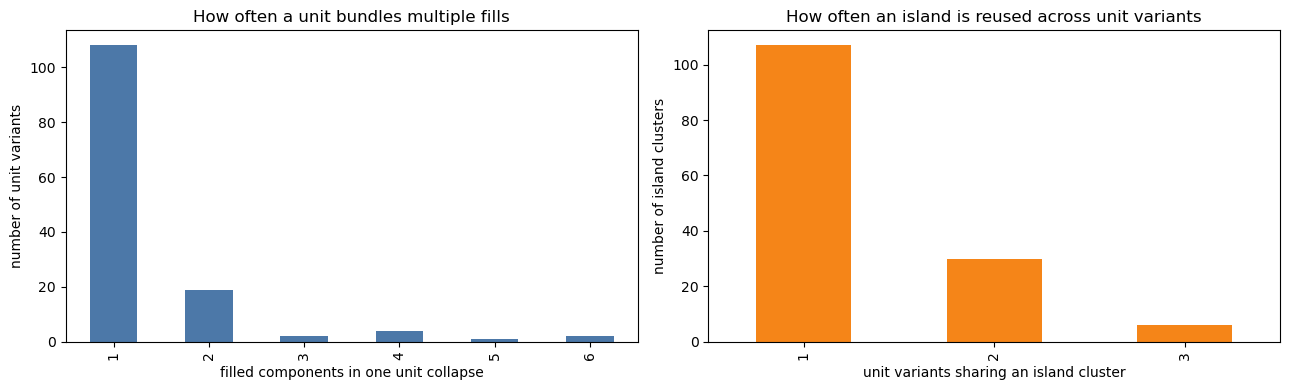

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
unit_fill_summary['n_filled_components'].value_counts().sort_index().plot.bar(ax=axes[0], color='#4C78A8')
axes[0].set(xlabel='filled components in one unit collapse', ylabel='number of unit variants',
            title='How often a unit bundles multiple fills')
island_crosswalk['n_unit_variants'].value_counts().sort_index().plot.bar(ax=axes[1], color='#F58518')
axes[1].set(xlabel='unit variants sharing an island cluster', ylabel='number of island clusters',
            title='How often an island is reused across unit variants')
plt.tight_layout()

## Match realised fills back to base land-component labels

This is the direct test of the bank-label idea. A fill is rasterised into the base label raster and assigned to the land-component label covering most of it. The result is a **candidate island identifier** only; it still needs an enclosed/topological eligibility test.

In [8]:
label_candidates = sorted((EXPERIMENT_DIR / 'boundary_components').glob('*land_water_labels*.tif'))
if not label_candidates:
    raise FileNotFoundError('No base boundary-component label raster found in boundary_components.')
LABEL_PATH = label_candidates[0]

def dominant_land_label(geometry, source):
    window = rasterio.windows.from_bounds(*geometry.bounds, transform=source.transform).round_offsets().round_lengths()
    window = window.intersection(rasterio.windows.Window(0, 0, source.width, source.height))
    values = source.read(1, window=window)
    mask = rasterize([(geometry, 1)], out_shape=values.shape, transform=source.window_transform(window),
                     fill=0, all_touched=False, dtype='uint8').astype(bool)
    labels, counts = np.unique(values[mask], return_counts=True)
    # value 1 is water; land labels begin at 2.
    keep = labels > 1
    if not np.any(keep):
        return pd.NA, 0.0
    labels, counts = labels[keep], counts[keep]
    best = int(np.argmax(counts))
    return int(labels[best]), float(counts[best] / counts.sum())

with rasterio.open(LABEL_PATH) as source:
    label_results = [dominant_land_label(geometry, source) for geometry in fills.geometry]
fills['base_land_label'] = [result[0] for result in label_results]
fills['base_land_label_coverage'] = [result[1] for result in label_results]

display(fills[['unit_id', 'edit_index', 'island_cluster_id', 'area_km2', 'base_land_label',
               'base_land_label_coverage']].sort_values('base_land_label_coverage').head(20))
print('Median dominant-label coverage:', fills['base_land_label_coverage'].median())

,unit_id,edit_index,island_cluster_id,area_km2,base_land_label,base_land_label_coverage
52,107,3,52,0.000020,<NA>,0.000000
95,122,2,90,0.000020,<NA>,0.000000
76,78,2,73,0.000020,<NA>,0.000000
140,36,3,123,0.000020,<NA>,0.000000
7,17,3,8,0.000020,<NA>,0.000000
144,36,7,8,0.000020,<NA>,0.000000
37,117,2,37,0.000020,<NA>,0.000000
22,47,2,22,0.000020,<NA>,0.000000
172,126,2,90,0.000020,<NA>,0.000000
100,51,0,95,4.622841,77,0.338201


Median dominant-label coverage: 1.0


## Base-41 diagnostic: link 366

This cell is intentionally parameterised: set `FOCAL_LINK_ID` to inspect another apparent side-channel case. It reports the unit(s) that contain the link and every individual fill bundled by those units.

In [9]:
FOCAL_LINK_ID = 366
focal_units = sorted(unit_membership.loc[unit_membership['id_link'].eq(FOCAL_LINK_ID), 'unit_id'].unique())
focal_unit_ids = set(map(int, focal_units))
focal_link = base_links.loc[base_links['id_link'].eq(FOCAL_LINK_ID)]
print('Units containing focal link:', focal_units)
display(focal_link[[c for c in ['id_link', 'id_us_node', 'id_ds_node', 'len', 'len_adj', 'wid', 'wid_adj'] if c in focal_link]].drop(columns='geometry', errors='ignore'))
display(unit_summary.loc[unit_summary['unit_id'].isin(focal_units)])
display(fills.loc[fills['unit_id'].isin(focal_units),
                  ['unit_id', 'edit_index', 'island_cluster_id', 'base_land_label', 'area_km2', 'compactness']].sort_values('area_km2', ascending=False))

Units containing focal link: [126]


,id_link,id_us_node,id_ds_node,len,len_adj,wid,wid_adj
366,366,252,245,8898.967628,8526.524853,269.366964,266.307356


,unit_id,bifurcation,confluence,n_paths,class,min_path_length,max_path_length,unit_node_ids,unit_node_count,internal_bifurcations,internal_confluences,children,parents,primary_parent_id,root_unit_id,depth_from_root,collapse_level,n_children,n_descendants,is_compound,path_cutoff_used,path_enumeration_truncated,compound_unit_id,compound_bubble_id,in_compound_bubble,compound_bubble_role
125,126,256,247,6,compound_or_nested_complex,15480.774364,25973.946323,"241,242,243,244,245,246,247,248,249,252,253,256,257,273",14,"[242, 245, 246, 257, 273]","[241, 243, 244, 248, 249, 252, 253]","[120, 122, 127, 136]",[],NaN,126,0,1,4,4,True,13,False,126.0,37,True,bubble_member


,unit_id,edit_index,island_cluster_id,base_land_label,area_km2,compactness
176,126,6,139,128,59.403422,0.250115
174,126,4,91,126,1.015366,0.236239
177,126,7,83,143,0.257077,0.259708
173,126,3,69,131,0.064164,0.303783
175,126,5,13,132,0.028146,0.351876
172,126,2,90,<NA>,0.000020,0.785398


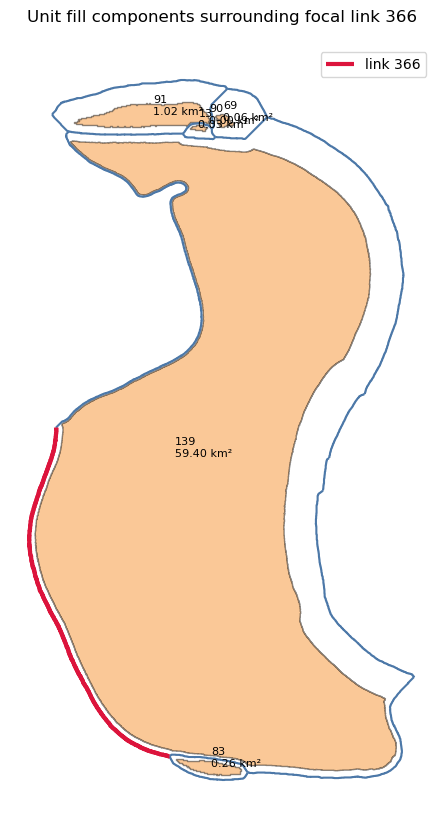

In [10]:
# Spatial review map for the focal case.
focal_unit_ids = set(map(int, focal_units))
focal_links = unit_membership.loc[unit_membership['unit_id'].isin(focal_unit_ids), 'id_link'].unique()
local_links = base_links.loc[base_links['id_link'].isin(focal_links)]
local_fills = fills.loc[fills['unit_id'].isin(focal_unit_ids)]

ax = local_fills.plot(facecolor='#F58518', edgecolor='black', alpha=.45, figsize=(10, 10))
local_links.plot(ax=ax, color='#4C78A8', linewidth=1.5)
focal_link.plot(ax=ax, color='crimson', linewidth=3, label=f'link {FOCAL_LINK_ID}')
for row in local_fills.itertuples():
    point = row.geometry.representative_point()
    ax.annotate(f'{row.island_cluster_id}\n{row.area_km2:.2f} km²', (point.x, point.y), fontsize=8)
ax.set_title(f'Unit fill components surrounding focal link {FOCAL_LINK_ID}')
ax.legend()
ax.set_axis_off()

## Candidate screen for a paired pilot

These are screening labels—not a final ranking. A future island-only treatment should normally require: (a) a dominant base land-component label, (b) a non-trivial filled area, and (c) a clear relation to one or more directed unit paths. The first pilot should deliberately include both one-to-one and disagreement cases.

In [11]:
cluster_label = (
    fills.groupby('island_cluster_id', as_index=False)
    .agg(base_land_label=('base_land_label', lambda x: x.dropna().mode().iloc[0] if not x.dropna().empty else pd.NA),
         min_label_coverage=('base_land_label_coverage', 'min'),
         n_units=('unit_id', 'nunique'),
         unit_ids=('unit_id', lambda x: tuple(sorted(set(map(int, x))))),
         max_area_km2=('area_km2', 'max'),
         geometry=('geometry', 'first'))
)
pilot_candidates = gpd.GeoDataFrame(cluster_label, geometry='geometry', crs=fills.crs)
pilot_candidates['high_confidence_label_match'] = pilot_candidates['min_label_coverage'].ge(.95)
pilot_candidates['unit_relation'] = np.select(
    [pilot_candidates['n_units'].eq(1), pilot_candidates['n_units'].gt(1)],
    ['unit-specific', 'shared-across-units'], default='unresolved'
)
pilot_candidates['suggested_pilot_role'] = np.select(
    [pilot_candidates['high_confidence_label_match'] & pilot_candidates['n_units'].eq(1),
     pilot_candidates['high_confidence_label_match'] & pilot_candidates['n_units'].gt(1)],
    ['matched unit–island case', 'unit–island disagreement case'], default='needs visual review'
)
display(pilot_candidates.sort_values(['suggested_pilot_role', 'max_area_km2'], ascending=[True, False]).head(30))

,island_cluster_id,base_land_label,min_label_coverage,n_units,unit_ids,max_area_km2,geometry,high_confidence_label_match,unit_relation,suggested_pilot_role
138,139,128,1.0,1,"(126,)",59.403422,"POLYGON ((314087.639 7183417.782, 314087.639 7183413.306, 314078.688 7183413.306, 314078.688 7183408.83, 314065.26 7...",True,unit-specific,matched unit–island case
142,143,15,1.0,1,"(33,)",27.028257,"POLYGON ((484269.666 7226922.221, 484269.666 7226913.269, 484211.481 7226913.269, 484211.481 7226899.842, 484148.82 ...",True,unit-specific,matched unit–island case
136,137,127,1.0,1,"(121,)",21.945717,"POLYGON ((312856.804 7183440.16, 312856.804 7183435.685, 312852.328 7183435.685, 312852.328 7183431.209, 312847.852 ...",True,unit-specific,matched unit–island case
139,140,96,1.0,1,"(95,)",11.555153,"POLYGON ((435886.642 7203473.686, 435886.642 7203469.21, 435832.933 7203469.21, 435832.933 7203464.735, 435721.039 7...",True,unit-specific,matched unit–island case
141,142,34,1.0,1,"(26,)",11.011932,"POLYGON ((498283.287 7227660.722, 498283.287 7227656.246, 498278.812 7227656.246, 498278.812 7227647.295, 498274.336...",True,unit-specific,matched unit–island case
126,127,137,1.0,1,"(129,)",8.023968,"POLYGON ((331744.533 7174994.391, 331744.533 7174985.44, 331726.63 7174985.44, 331726.63 7174976.488, 331663.97 7174...",True,unit-specific,matched unit–island case
131,132,111,1.0,1,"(103,)",7.609236,"POLYGON ((413073.666 7197082.293, 413073.666 7197073.342, 413046.812 7197073.342, 413046.812 7197064.39, 413037.86 7...",True,unit-specific,matched unit–island case
130,131,89,1.0,1,"(86,)",7.453223,"POLYGON ((447541.535 7207819.654, 447541.535 7207815.179, 447537.06 7207815.179, 447537.06 7207810.703, 447528.108 7...",True,unit-specific,matched unit–island case
128,129,18,1.0,1,"(15,)",7.166117,"POLYGON ((477641.057 7223431.124, 477641.057 7223417.697, 477600.776 7223417.697, 477600.776 7223422.172, 477529.163...",True,unit-specific,matched unit–island case
73,74,17,1.0,1,"(78,)",6.919117,"POLYGON ((469463.834 7219801.278, 469463.834 7219796.803, 469450.407 7219796.803, 469450.407 7219792.327, 469436.979...",True,unit-specific,matched unit–island case


## Local RivGraph topology experiment

The following cells create diagnostic *cropped* RivGraph networks for the base mask, the full focal-unit fill, and each individual focal fill. They are intentionally not complete child states: cropping introduces artificial inlet/outlet boundaries, and there is no direction assignment, hydraulic reconstruction, or routing. They answer the narrower question: **does each individual island fill remove or reorganise the focal local anabranching?**

Set `RUN_LOCAL_RIVGRAPH = True` only when ready to write the diagnostic outputs. Existing case folders are preserved and skipped; delete or change `LOCAL_OUTPUT_DIR` explicitly to make a fresh run.

In [12]:
RUN_LOCAL_RIVGRAPH = False  # Deliberate opt-in: this writes masks and RivGraph products.
LOCAL_HALO_M = 5_000.0
LOCAL_OUTPUT_DIR = EXPERIMENT_DIR / 'island_diagnostic' / f'link_{FOCAL_LINK_ID}'
LOCAL_EXIT_SIDES = json.loads((BASE_VARIANT / 'summary' / 'variant_manifest.json').read_text())['exit_sides']

focal_fill_rows = fills.loc[fills['unit_id'].isin(focal_unit_ids)].copy()
focal_link_ids = unit_membership.loc[unit_membership['unit_id'].isin(focal_unit_ids), 'id_link'].unique()
local_links = base_links.loc[base_links['id_link'].isin(focal_link_ids)].copy()
# One case per visible, non-trivial island plus a full-unit comparison. Tiny one-pixel edits remain in
# the all-components case but are omitted as stand-alone diagnostic networks.
MIN_SINGLE_ISLAND_AREA_KM2 = 1e-4
single_islands = focal_fill_rows.loc[focal_fill_rows['area_km2'].ge(MIN_SINGLE_ISLAND_AREA_KM2)].copy()
LOCAL_CASES = {'base': []}
LOCAL_CASES['all_focal_unit_fills'] = focal_fill_rows.index.tolist()
for row in single_islands.sort_values('area_km2', ascending=False).itertuples():
    LOCAL_CASES[f'island_cluster_{int(row.island_cluster_id)}'] = [int(row.Index)]

print('Output root:', LOCAL_OUTPUT_DIR)
print('Exit sides inherited from the base experiment:', LOCAL_EXIT_SIDES)
pd.DataFrame({'case_id': list(LOCAL_CASES), 'n_fill_components': [len(v) for v in LOCAL_CASES.values()]})

Output root: /Volumes/PhD/river_hierarchy/network_variants/output/41_indep__anchored/island_diagnostic/link_366
Exit sides inherited from the base experiment: EW


,case_id,n_fill_components
0,base,0
1,all_focal_unit_fills,6
2,island_cluster_139,1
3,island_cluster_91,1
4,island_cluster_83,1
5,island_cluster_69,1
6,island_cluster_13,1


In [13]:
def focal_crop_window(mask_path: Path, halo_m: float) -> Window:
    context = pd.concat([
        local_links[['geometry']],
        focal_fill_rows[['geometry']],
    ], ignore_index=True)
    minx, miny, maxx, maxy = gpd.GeoSeries(context.geometry, crs=base_links.crs).total_bounds
    with rasterio.open(mask_path) as source:
        window = from_bounds(minx - halo_m, miny - halo_m, maxx + halo_m, maxy + halo_m, source.transform)
        return window.round_offsets().round_lengths().intersection(Window(0, 0, source.width, source.height))

BASE_MASK_PATH = next((BASE_VARIANT / 'mask').glob('*S000_base_collapsed.tif'))
LOCAL_WINDOW = focal_crop_window(BASE_MASK_PATH, LOCAL_HALO_M)

def write_local_case_mask(case_id: str, fill_indices: list[int]) -> Path:
    case_dir = LOCAL_OUTPUT_DIR / case_id
    mask_path = case_dir / 'mask.tif'
    case_dir.mkdir(parents=True, exist_ok=True)
    if mask_path.exists():
        return mask_path
    with rasterio.open(BASE_MASK_PATH) as source:
        base = source.read(1, window=LOCAL_WINDOW) > 0
        profile = source.profile.copy()
        transform = source.window_transform(LOCAL_WINDOW)
    additions = np.zeros(base.shape, dtype=bool)
    for geometry in fills.loc[fill_indices, 'geometry']:
        additions |= rasterize([(geometry, 1)], out_shape=base.shape, transform=transform,
                               fill=0, all_touched=False, dtype='uint8').astype(bool)
    profile.update(height=base.shape[0], width=base.shape[1], transform=transform, dtype='uint8', count=1, compress='lzw')
    with rasterio.open(mask_path, 'w', **profile) as destination:
        destination.write((base | additions).astype('uint8'), 1)
    (case_dir / 'case_manifest.json').write_text(json.dumps({
        'case_id': case_id, 'focal_link_id': int(FOCAL_LINK_ID), 'focal_unit_ids': sorted(map(int, focal_unit_ids)),
        'fill_row_indices': list(map(int, fill_indices)), 'fill_cluster_ids': fills.loc[fill_indices, 'island_cluster_id'].astype(int).tolist(),
        'crop_window': {'col_off': int(LOCAL_WINDOW.col_off), 'row_off': int(LOCAL_WINDOW.row_off),
                        'width': int(LOCAL_WINDOW.width), 'height': int(LOCAL_WINDOW.height)},
        'exit_sides': LOCAL_EXIT_SIDES, 'scope': 'diagnostic_cropped_rivgraph_only'
    }, indent=2))
    return mask_path

case_masks = {case_id: write_local_case_mask(case_id, fill_indices) for case_id, fill_indices in LOCAL_CASES.items()}
print('Prepared diagnostic masks:', list(case_masks))

Prepared diagnostic masks: ['base', 'all_focal_unit_fills', 'island_cluster_139', 'island_cluster_91', 'island_cluster_83', 'island_cluster_69', 'island_cluster_13']


In [14]:
if RUN_LOCAL_RIVGRAPH:
    from network_variants.variant_generation import _run_rivgraph

    for case_id, mask_path in case_masks.items():
        case_dir = LOCAL_OUTPUT_DIR / case_id
        existing = list((case_dir / 'rivgraph').glob('*links.gpkg')) if (case_dir / 'rivgraph').exists() else []
        if existing:
            print(f'Skipping {case_id}: RivGraph links already exist.')
            continue
        print(f'Running RivGraph for {case_id} …')
        _run_rivgraph(
            run_name=f'{EXAMPLE_ID}_link_{FOCAL_LINK_ID}_{case_id}',
            collapsed_mask_path=mask_path,
            rivgraph_output_dir=case_dir / 'rivgraph',
            exit_sides=LOCAL_EXIT_SIDES,
            single_thread=True, export_sword=False, verbose=False,
            metadata={'diagnostic_scope': 'cropped_individual_island_test', 'case_id': case_id},
        )
else:
    print('RivGraph runs disabled. Review the cases, then set RUN_LOCAL_RIVGRAPH = True.')

RivGraph runs disabled. Review the cases, then set RUN_LOCAL_RIVGRAPH = True.


In [15]:
# This cell is useful after RivGraph runs complete; it is safe to run before then.
topology_rows = []
for case_id in LOCAL_CASES:
    case_dir = LOCAL_OUTPUT_DIR / case_id / 'rivgraph'
    link_paths = list(case_dir.glob('*links.gpkg')) if case_dir.exists() else []
    node_paths = list(case_dir.glob('*nodes.gpkg')) if case_dir.exists() else []
    if not link_paths or not node_paths:
        continue
    links = gpd.read_file(link_paths[0])
    nodes = gpd.read_file(node_paths[0])
    topology_rows.append({
        'case_id': case_id, 'n_links': len(links), 'n_nodes': len(nodes),
        # Local RivGraph has no flow directions, so this is an undirected junction count.
        'n_junctions': int((pd.to_numeric(nodes['n_links'], errors='coerce') > 2).sum()),
        'total_link_length_m': float(pd.to_numeric(links.get('len'), errors='coerce').sum()),
    })
local_topology_summary = pd.DataFrame(topology_rows).sort_values('case_id') if topology_rows else pd.DataFrame()
if not local_topology_summary.empty and 'base' in set(local_topology_summary['case_id']):
    base_metrics = local_topology_summary.set_index('case_id').loc['base']
    for metric in ('n_links', 'n_nodes', 'n_junctions', 'total_link_length_m'):
        local_topology_summary[f'delta_{metric}_vs_base'] = local_topology_summary[metric] - base_metrics[metric]
display(local_topology_summary)

,case_id,n_links,n_nodes,n_junctions,total_link_length_m,delta_n_links_vs_base,delta_n_nodes_vs_base,delta_n_junctions_vs_base,delta_total_link_length_m_vs_base
1,all_focal_unit_fills,18,14,11,64918.741097,-15.0,-10.0,-10.0,-26712.301008
0,base,33,24,21,91631.042104,0.0,0.0,0.0,0.000000
6,island_cluster_13,30,22,19,90783.609214,-3.0,-2.0,-2.0,-847.432890
2,island_cluster_139,30,22,19,83692.626350,-3.0,-2.0,-2.0,-7938.415754
5,island_cluster_69,30,22,19,90117.170010,-3.0,-2.0,-2.0,-1513.872094
4,island_cluster_83,30,22,19,89588.788793,-3.0,-2.0,-2.0,-2042.253311
3,island_cluster_91,30,22,19,89242.255725,-3.0,-2.0,-2.0,-2388.786379


## Example 56: isolate the main water body before identifying islands

This is the proposed first eligibility check. The base water mask can contain detached wet pixels or small external water bodies. We retain only its largest 8-connected water component, then define provisional islands as dry 8-connected components that do **not** touch the raster edge. This deliberately separates the island question from the existing bank-label raster.

Nothing in this section is written back to the experiment: it is a read-only inventory and visual check.

In [16]:
ISLAND_SCREEN_EXAMPLE_ID = '56'
TINY_WATER_COMPONENT_PIXELS = 9
TINY_ISLAND_PIXELS = 9

island_screen_dir = Path(f'/Volumes/PhD/river_hierarchy/network_variants/output/{ISLAND_SCREEN_EXAMPLE_ID}_indep__anchored')
island_screen_base = island_screen_dir / 'states' / 'S000_base' / 'variant'
island_screen_mask_path = next((island_screen_base / 'mask').glob('*_collapsed.tif'))
island_screen_links_path = next((island_screen_base / 'directed').glob('*directed_links.gpkg'))
print('Screening mask:', island_screen_mask_path)

Screening mask: /Volumes/PhD/river_hierarchy/network_variants/output/56_indep__anchored/states/S000_base/variant/mask/56__S000_base_collapsed.tif


In [17]:
with rasterio.open(island_screen_mask_path) as source:
    screen_water = source.read(1) > 0
    screen_transform = source.transform
    screen_crs = source.crs
    screen_pixel_area_m2 = abs(source.transform.a * source.transform.e)

water_labels, n_water_components = nd_label(screen_water, structure=np.ones((3, 3), dtype=np.uint8))
water_pixels = np.bincount(water_labels.ravel())
main_water_label = int(np.argmax(water_pixels[1:]) + 1)
main_water = water_labels == main_water_label

water_slices = find_objects(water_labels)
water_rows = []
for component_id in range(1, n_water_components + 1):
    component_slice = water_slices[component_id - 1]
    n_pixels = int(water_pixels[component_id])
    water_rows.append({
        'water_component_id': component_id,
        'is_main_water': component_id == main_water_label,
        'n_pixels': n_pixels,
        'area_m2': n_pixels * screen_pixel_area_m2,
        'row_min': component_slice[0].start, 'row_max': component_slice[0].stop - 1,
        'col_min': component_slice[1].start, 'col_max': component_slice[1].stop - 1,
    })
water_component_summary = pd.DataFrame(water_rows).sort_values('n_pixels', ascending=False)
detached_water_components = water_component_summary.loc[~water_component_summary['is_main_water']].copy()
tiny_water_outliers = detached_water_components.loc[detached_water_components['n_pixels'] <= TINY_WATER_COMPONENT_PIXELS]

print(f'Water components: {n_water_components}; main component contains {main_water.sum() / screen_water.sum():.3%} of all wet pixels.')
print(f'Detached components: {len(detached_water_components)}; tiny detached components (≤ {TINY_WATER_COMPONENT_PIXELS} px): {len(tiny_water_outliers)}')
display(water_component_summary.head(15))
display(tiny_water_outliers.head(50))

Water components: 35; main component contains 99.885% of all wet pixels.
Detached components: 34; tiny detached components (≤ 9 px): 14


,water_component_id,is_main_water,n_pixels,area_m2,row_min,row_max,col_min,col_max
0,1,True,1410602,7.553684e+07,848,8650,556,9064
28,29,False,416,2.227654e+04,7288,7303,2194,2235
17,18,False,249,1.333379e+04,3991,4012,6248,6264
27,28,False,141,7.550461e+03,7262,7282,2858,2884
2,3,False,135,7.229165e+03,1866,1889,8128,8157
23,24,False,124,6.640121e+03,5534,5546,5638,5657
8,9,False,82,4.391048e+03,2710,2729,7350,7360
29,30,False,57,3.052314e+03,7298,7304,2182,2192
13,14,False,52,2.784567e+03,3122,3130,7475,7485
7,8,False,43,2.302623e+03,2527,2533,7426,7433


,water_component_id,is_main_water,n_pixels,area_m2,row_min,row_max,col_min,col_max
18,19,False,9,481.944302,4267,4272,6029,6030
11,12,False,9,481.944302,2735,2739,7355,7356
9,10,False,9,481.944302,2711,2714,7706,7708
21,22,False,5,267.746835,5104,5107,6076,6077
32,33,False,4,214.197468,7611,7613,1841,1843
5,6,False,4,214.197468,1957,1958,8055,8056
22,23,False,3,160.648101,5110,5111,6078,6079
3,4,False,2,107.098734,1888,1889,8126,8126
26,27,False,1,53.549367,6352,6352,4091,4091
25,26,False,1,53.549367,5830,5830,5802,5802


In [18]:
# 8-connectivity joins diagonally touching dry pixels into one island. This avoids
# promoting a corner-touching pixel to a separate collapse candidate.
land_structure = np.ones((3, 3), dtype=np.uint8)
island_labels, n_land_components = nd_label((~main_water).astype(np.uint8), structure=land_structure)
land_pixels = np.bincount(island_labels.ravel())
edge_labels = np.unique(np.concatenate([island_labels[0], island_labels[-1], island_labels[:, 0], island_labels[:, -1]]))
edge_labels = {int(value) for value in edge_labels if value > 0}
land_slices = find_objects(island_labels)
island_rows = []
for component_id in range(1, n_land_components + 1):
    component_slice = land_slices[component_id - 1]
    n_pixels = int(land_pixels[component_id])
    island_rows.append({
        'island_component_id': component_id,
        'n_pixels': n_pixels,
        'area_m2': n_pixels * screen_pixel_area_m2,
        'touches_raster_edge': component_id in edge_labels,
        'is_provisional_island': component_id not in edge_labels,
        'row_min': component_slice[0].start, 'row_max': component_slice[0].stop - 1,
        'col_min': component_slice[1].start, 'col_max': component_slice[1].stop - 1,
    })
island_component_summary = pd.DataFrame(island_rows).sort_values('area_m2', ascending=False)
provisional_islands = island_component_summary.loc[island_component_summary['is_provisional_island']].copy()
tiny_island_outliers = provisional_islands.loc[provisional_islands['n_pixels'] <= TINY_ISLAND_PIXELS]

print(f'Dry components after retaining only main water: {n_land_components}')
print(f'Provisional enclosed islands: {len(provisional_islands)}; tiny candidates (≤ {TINY_ISLAND_PIXELS} px): {len(tiny_island_outliers)}')
display(provisional_islands.head(30))
display(tiny_island_outliers.head(50))

Dry components after retaining only main water: 17
Provisional enclosed islands: 16; tiny candidates (≤ 9 px): 1


,island_component_id,n_pixels,area_m2,touches_raster_edge,is_provisional_island,row_min,row_max,col_min,col_max
4,5,370164,1.982205e+07,False,True,2153,3458,7024,7792
10,11,289156,1.548412e+07,False,True,5023,5864,5216,5992
12,13,87387,4.679519e+06,False,True,6159,6432,4356,4875
7,8,21822,1.168554e+06,False,True,3684,3943,6405,6645
3,4,13442,7.198106e+05,False,True,1619,1779,8121,8294
16,17,10348,5.541288e+05,False,True,8277,8462,807,938
8,9,8126,4.351422e+05,False,True,4453,4681,6034,6125
9,10,4785,2.562337e+05,False,True,4719,4913,6043,6092
15,16,3968,2.124839e+05,False,True,7767,7870,1395,1539
2,3,2761,1.478498e+05,False,True,1502,1589,8301,8398


,island_component_id,n_pixels,area_m2,touches_raster_edge,is_provisional_island,row_min,row_max,col_min,col_max
1,2,1,53.549367,False,True,1501,1501,8399,8399


In [19]:
# Interactive display in raster-pixel coordinates. This avoids mixing projected link coordinates
# with image pixel coordinates, which made the previous Matplotlib plot appear blank.
import plotly.graph_objects as go

PLOT_DOWNSAMPLE = 8  # display only; component calculations above remain full resolution
provisional_island_mask = (island_labels > 0) & ~np.isin(island_labels, list(edge_labels))
display_rgb = np.full((*screen_water.shape, 3), 248, dtype=np.uint8)
display_rgb[screen_water] = (170, 170, 170)       # detached water
display_rgb[main_water] = (78, 121, 167)          # retained main water
display_rgb[provisional_island_mask] = (245, 133, 24)  # enclosed islands
display_rgb = display_rgb[::PLOT_DOWNSAMPLE, ::PLOT_DOWNSAMPLE]

screen_links = gpd.read_file(island_screen_links_path).to_crs(screen_crs)
inverse_transform = ~screen_transform
line_x, line_y = [], []
for geometry in screen_links.geometry:
    if geometry is None or geometry.is_empty:
        continue
    parts = geometry.geoms if geometry.geom_type == 'MultiLineString' else [geometry]
    for part in parts:
        coordinates = np.asarray(part.coords)
        columns, rows = inverse_transform * (coordinates[:, 0], coordinates[:, 1])
        line_x.extend((columns / PLOT_DOWNSAMPLE).tolist() + [None])
        line_y.extend((rows / PLOT_DOWNSAMPLE).tolist() + [None])

fig = go.Figure(go.Image(z=display_rgb))
fig.add_trace(go.Scattergl(x=line_x, y=line_y, mode='lines', name='Directed centreline',
                           line={'color': 'black', 'width': 1}, hoverinfo='skip'))
fig.add_trace(go.Scatter(x=[None], y=[None], mode='markers', name='Orange: provisional enclosed island',
                         marker={'color': 'rgb(245, 133, 24)'}))
fig.update_layout(title=f'Example {ISLAND_SCREEN_EXAMPLE_ID}: main water body and provisional enclosed islands',
                  template='plotly_white', width=1000, height=850,
                  margin={'l': 10, 'r': 10, 't': 55, 'b': 10})
fig.update_xaxes(visible=False, scaleanchor='y', scaleratio=1)
fig.update_yaxes(visible=False, autorange='reversed')
fig.show()

# Zoom and pan to inspect candidates; tables above provide exact IDs and pixel areas.

## Island-to-unit and island-to-network crosswalk

The cleaned raster labels are now promoted to stable, example-specific island IDs. Each island is compared with the `edit/add` geometry already realised by every independent unit variant, then linked to nearby directed centreline segments. This is still a diagnostic: overlap means the current unit treatment filled that island; it does not itself prove that the island is a valid routing intervention.

In [20]:
# Vectorise each enclosed label once. IDs are deterministic for this fixed base mask.
island_features = []
for geometry_mapping, label_value in shapes(
    island_labels.astype(np.int32), mask=provisional_island_mask, transform=screen_transform
):
    component_id = int(label_value)
    island_features.append({'island_component_id': component_id, 'geometry': shapely_shape(geometry_mapping)})
island_gdf = gpd.GeoDataFrame(island_features, geometry='geometry', crs=screen_crs)
island_gdf = island_gdf.merge(
    provisional_islands.drop(columns=['is_provisional_island']), on='island_component_id', how='left'
).sort_values('area_m2', ascending=False).reset_index(drop=True)
island_gdf['island_id'] = [f'island_{ISLAND_SCREEN_EXAMPLE_ID}_{value:03d}' for value in island_gdf['island_component_id']]
island_gdf['area_km2'] = island_gdf['area_m2'] / 1e6
display(island_gdf[['island_id', 'island_component_id', 'n_pixels', 'area_km2', 'touches_raster_edge']])

/opt/anaconda3/envs/river-hierarchy-rivgraph/lib/python3.12/site-packages/rasterio/features.py:129: RuntimeWarning: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.
  yield from _shapes(source, mask, connectivity, transform)


,island_id,island_component_id,n_pixels,area_km2,touches_raster_edge
0,island_56_005,5,370164,19.822048,False
1,island_56_011,11,289156,15.484121,False
2,island_56_013,13,87387,4.679519,False
3,island_56_008,8,21822,1.168554,False
4,island_56_004,4,13442,0.719811,False
5,island_56_017,17,10348,0.554129,False
6,island_56_009,9,8126,0.435142,False
7,island_56_010,10,4785,0.256234,False
8,island_56_016,16,3968,0.212484,False
9,island_56_003,3,2761,0.147850,False


In [21]:
# Collect only actual water-addition geometries from the current independent-unit states.
unit_fill_records = []
for fill_path in sorted((island_screen_dir / 'states').glob('S*_unit_*/variant/mask/collapse_edit_geometries.gpkg')):
    state_name = fill_path.parents[2].name
    unit_match = re.search(r'_unit_(\d+)$', state_name)
    if unit_match is None:
        continue
    fills_for_unit = gpd.read_file(fill_path)
    fills_for_unit = fills_for_unit.loc[
        fills_for_unit['action'].eq('add') & fills_for_unit['geometry'].notna()
    ].copy()
    fills_for_unit['unit_id'] = int(unit_match.group(1))
    fills_for_unit['state_name'] = state_name
    unit_fill_records.append(fills_for_unit)
current_unit_fills = gpd.GeoDataFrame(
    pd.concat(unit_fill_records, ignore_index=True), geometry='geometry', crs=screen_crs
)
screen_links = gpd.read_file(island_screen_links_path).to_crs(screen_crs)
NEARBY_LINK_BUFFER_M = 500.0

crosswalk_rows = []
for island in island_gdf.itertuples():
    matching_fills = current_unit_fills.loc[current_unit_fills.intersects(island.geometry)].copy()
    if not matching_fills.empty:
        matching_fills['overlap_m2'] = matching_fills.geometry.intersection(island.geometry).area
        matching_fills['overlap_fraction_of_island'] = matching_fills['overlap_m2'] / island.geometry.area
        matching_fills = matching_fills.loc[matching_fills['overlap_m2'] > 0]
    nearby = screen_links.loc[screen_links.intersects(island.geometry.buffer(NEARBY_LINK_BUFFER_M))]
    crosswalk_rows.append({
        'island_id': island.island_id,
        'island_component_id': int(island.island_component_id),
        'area_km2': island.area_km2,
        'n_pixels': int(island.n_pixels),
        'current_unit_ids': ', '.join(map(str, sorted(matching_fills['unit_id'].unique()))) if len(matching_fills) else '',
        'n_matching_unit_fills': int(len(matching_fills)),
        'max_fill_overlap_fraction': float(matching_fills['overlap_fraction_of_island'].max()) if len(matching_fills) else 0.0,
        'nearby_link_ids': ', '.join(map(str, sorted(nearby['id_link'].astype(int).tolist()))),
        'n_nearby_links': int(len(nearby)),
    })
island_unit_crosswalk = pd.DataFrame(crosswalk_rows).sort_values('area_km2', ascending=False).reset_index(drop=True)
display(island_unit_crosswalk)
print('Island crosswalk classes:')
print(pd.Series(np.select(
    [island_unit_crosswalk['n_matching_unit_fills'].eq(0), island_unit_crosswalk['n_matching_unit_fills'].eq(1)],
    ['not currently filled', 'filled by one unit'], default='filled by multiple units'
)).value_counts().to_string())

,island_id,island_component_id,area_km2,n_pixels,current_unit_ids,n_matching_unit_fills,max_fill_overlap_fraction,nearby_link_ids,n_nearby_links
0,island_56_005,5,19.822048,370164,4,1,1.0,"6, 7, 8, 9, 10, 11, 12, 13, 15",9
1,island_56_011,11,15.484121,289156,10,1,1.0,"24, 25, 26, 27, 28, 29",6
2,island_56_013,13,4.679519,87387,12,1,1.0,"30, 31, 32, 33, 34, 35",6
3,island_56_008,8,1.168554,21822,6,1,1.0,"14, 16, 17, 18",4
4,island_56_004,4,0.719811,13442,2,1,1.0,"1, 2, 3, 4, 5, 6",6
5,island_56_017,17,0.554129,10348,15,1,1.0,"42, 43, 44, 45",4
6,island_56_009,9,0.435142,8126,7,1,1.0,"18, 19, 20, 21, 22, 23",6
7,island_56_010,10,0.256234,4785,8,1,1.0,"19, 20, 21, 22, 23, 24, 25, 26",8
8,island_56_016,16,0.212484,3968,14,1,1.0,"39, 40, 41, 42",4
9,island_56_003,3,0.147850,2761,1,1,1.0,"0, 1, 2, 3, 4, 5",6


Island crosswalk classes:
filled by one unit          13
filled by multiple units     3


### Freeze the experimental candidate set

Every non-tiny enclosed island is retained for the pilot. A shared island is anchored to its most local current source unit: non-compound first, then greater hierarchy depth, then shorter maximum path. This explicitly chooses units 11, 9, and 3 for the shared islands 14, 12, and 6.

In [22]:
island_unit_summary = pd.read_csv(island_screen_dir / 'states' / 'S000_base' / 'hierarchy' / 'unit_summary.csv')
anchor_lookup = island_unit_summary.set_index('unit_id')

def proposed_anchor_unit(unit_ids_text):
    unit_ids = [int(value.strip()) for value in str(unit_ids_text).split(',') if value.strip()]
    if not unit_ids:
        return pd.NA
    candidates = anchor_lookup.loc[unit_ids].reset_index().sort_values(
        ['is_compound', 'depth_from_root', 'max_path_length', 'unit_id'],
        ascending=[True, False, True, True], kind='mergesort'
    )
    return int(candidates.iloc[0]['unit_id'])

island_candidate_registry = island_unit_crosswalk.copy()
island_candidate_registry['selection_status'] = np.where(
    island_candidate_registry['n_pixels'] <= TINY_ISLAND_PIXELS, 'exclude_raster_artifact', 'approved_pilot'
)
island_candidate_registry['proposed_anchor_unit_id'] = island_candidate_registry['current_unit_ids'].map(proposed_anchor_unit)
island_candidate_registry = island_candidate_registry.merge(
    island_unit_summary[['unit_id', 'bifurcation', 'confluence', 'is_compound', 'depth_from_root']].rename(columns={
        'unit_id': 'proposed_anchor_unit_id', 'bifurcation': 'anchor_bifurcation', 'confluence': 'anchor_confluence',
        'is_compound': 'anchor_unit_is_compound', 'depth_from_root': 'anchor_unit_depth',
    }), on='proposed_anchor_unit_id', how='left', validate='m:1'
)
island_candidate_registry['anchor_rule'] = 'noncompound_then_deeper_then_shorter_max_path'
display(island_candidate_registry)
print(island_candidate_registry['selection_status'].value_counts().to_string())

# Opt-in persistence: this creates the experimental registry, not any network variants.
WRITE_ISLAND_EXPERIMENT_SETUP = False
if WRITE_ISLAND_EXPERIMENT_SETUP:
    setup_dir = island_screen_dir / 'island_only_setup_8connected'
    setup_dir.mkdir(exist_ok=True)
    island_candidate_registry.to_csv(setup_dir / 'island_candidate_registry.csv', index=False)
    island_gdf.merge(island_candidate_registry, on=['island_id', 'island_component_id', 'n_pixels', 'area_km2'], how='left').to_file(
        setup_dir / 'island_candidate_geometries.gpkg', driver='GPKG'
    )
    setup_manifest = {
        'example_id': ISLAND_SCREEN_EXAMPLE_ID,
        'candidate_definition': 'enclosed dry 8-connected component within largest 8-connected water body',
        'excluded_island_ids': island_candidate_registry.loc[island_candidate_registry['selection_status'].eq('exclude_raster_artifact'), 'island_id'].tolist(),
        'approved_island_ids': island_candidate_registry.loc[island_candidate_registry['selection_status'].eq('approved_pilot'), 'island_id'].tolist(),
        'anchor_rule': 'noncompound_then_deeper_then_shorter_max_path',
    }
    (setup_dir / 'island_experiment_manifest.json').write_text(json.dumps(setup_manifest, indent=2))
    print('Wrote island experiment setup to', setup_dir)

FileNotFoundError: [Errno 2] No such file or directory: '/Volumes/PhD/river_hierarchy/network_variants/output/56_indep__anchored/states/S000_base/variant/hierarchy/unit_summary.csv'

In [ ]:
# Select any island ID from island_unit_crosswalk and rerun this cell for a local interactive review.
ISLAND_REVIEW_ID = island_unit_crosswalk.iloc[14]['island_id']
REVIEW_HALO_M = 2_000.0
review_island = island_gdf.set_index('island_id').loc[ISLAND_REVIEW_ID]
review_geometry = review_island.geometry
review_fills = current_unit_fills.loc[current_unit_fills.intersects(review_geometry)].copy()
review_links = screen_links.loc[screen_links.intersects(review_geometry.buffer(REVIEW_HALO_M))]
pixel_size_m = float(np.sqrt(screen_pixel_area_m2))
halo_pixels = int(np.ceil(REVIEW_HALO_M / pixel_size_m))
row_start = max(int(review_island.row_min) - halo_pixels, 0); row_stop = min(int(review_island.row_max) + halo_pixels + 1, screen_water.shape[0])
col_start = max(int(review_island.col_min) - halo_pixels, 0); col_stop = min(int(review_island.col_max) + halo_pixels + 1, screen_water.shape[1])
local_water = screen_water[row_start:row_stop, col_start:col_stop]
local_main_water = main_water[row_start:row_stop, col_start:col_stop]
local_islands = provisional_island_mask[row_start:row_stop, col_start:col_stop]
local_selected = island_labels[row_start:row_stop, col_start:col_stop] == int(review_island.island_component_id)
local_rgb = np.full((*local_water.shape, 3), 248, dtype=np.uint8)
local_rgb[local_water] = (170, 170, 170); local_rgb[local_main_water] = (78, 121, 167)
local_rgb[local_islands] = (245, 133, 24); local_rgb[local_selected] = (214, 39, 40)
local_rgb = local_rgb[::PLOT_DOWNSAMPLE, ::PLOT_DOWNSAMPLE]

def pixel_lines(frame, offset_col=0, offset_row=0):
    xs, ys = [], []
    for geometry in frame.geometry:
        if geometry is None or geometry.is_empty:
            continue
        linework = geometry.boundary if geometry.geom_type in {'Polygon', 'MultiPolygon'} else geometry
        parts = linework.geoms if hasattr(linework, 'geoms') else [linework]
        for part in parts:
            coordinates = np.asarray(part.coords)
            columns, rows = inverse_transform * (coordinates[:, 0], coordinates[:, 1])
            xs.extend(((columns - offset_col) / PLOT_DOWNSAMPLE).tolist() + [None])
            ys.extend(((rows - offset_row) / PLOT_DOWNSAMPLE).tolist() + [None])
    return xs, ys

link_x, link_y = pixel_lines(review_links, col_start, row_start)
fill_x, fill_y = pixel_lines(review_fills, col_start, row_start)
fig = go.Figure(go.Image(z=local_rgb))
fig.add_trace(go.Scattergl(x=link_x, y=link_y, mode='lines', name='Nearby directed links', line={'color': 'black', 'width': 1}, hoverinfo='skip'))
if fill_x:
    fig.add_trace(go.Scattergl(x=fill_x, y=fill_y, mode='lines', name='Current unit fill footprint', line={'color': '#6A3D9A', 'width': 2}, hoverinfo='skip'))
fig.update_layout(title=f'{ISLAND_REVIEW_ID}: red selected island; orange other islands', template='plotly_white', width=900, height=760, margin={'l': 10, 'r': 10, 't': 55, 'b': 10})
fig.update_xaxes(visible=False, scaleanchor='y', scaleratio=1); fig.update_yaxes(visible=False, autorange='reversed')
fig.show()
display(island_unit_crosswalk.loc[island_unit_crosswalk['island_id'].eq(ISLAND_REVIEW_ID)])

,island_id,island_component_id,area_km2,n_pixels,current_unit_ids,n_matching_unit_fills,max_fill_overlap_fraction,nearby_link_ids,n_nearby_links
14,island_56_006,6,0.046802,874,"3, 4",2,1.0,"7, 9, 10, 11",4


## Decision gates before implementation

Proceed to a small paired routing pilot only if visual review confirms that selected candidates are enclosed islands and each has a clear directed bypass interpretation. Start with 6–12 cases across examples: simple two-path units, unit-specific islands, shared/nested islands, and the link-366-type compound case.

Do **not** use the raw count of land labels as the future number of variants. The appropriate candidate count comes after excluding mainland-connected components, raster artefacts, and components without a defensible channel-bypass relation.